# Part 0: Cleaning a raw sensor dataset (Kanpur, Jul–Aug 2026)

**Input:** `kanpur_pm25_raw_jul_aug_2026.csv`. Wide format on a 15-minute UTC grid, with three columns per sensor:
`<id>_latitude`, `<id>_longitude`, `<id>_pm25`.

**Output:** `kanpur_hourly_clean.csv`. A long hourly table with a `flag` column. Problems are **flagged, never deleted**,
and missing hours stay missing (no gap filling).

Steps, matching the assignment:
1. Understand the format
2. Reshape to hourly
3. Detect and flag problems
4. Write the clean file
5. Calibration check between the two ID families
6. Before/after summary and the daily cycle in IST

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
SEED = 0
np.random.seed(SEED)


def find_data_dir():
    """Locate the course data folder. Set the MP1_DATA environment variable to override."""
    cands = [os.environ.get("MP1_DATA", ""), "data", "../mp1-package/data",
             "../../Desktop/CS771/Miniproj1/mp1-package/data", "../data"]
    for c in cands:
        if c and (Path(c) / "kanpur_pm25_raw_jul_aug_2026.csv").exists():
            return Path(c)
    raise FileNotFoundError("Course data not found: set MP1_DATA to the mp1-package/data folder")


DATA = find_data_dir()
OUT_CSV = Path("kanpur_hourly_clean.csv")
print("data folder:", DATA.resolve())

data folder: C:\Users\HP\Desktop\CS771\Miniproj1\mp1-package\data


## 0.1 Understand the format

In [2]:
raw = pd.read_csv(DATA / "kanpur_pm25_raw_jul_aug_2026.csv")
raw["timestamp_utc"] = pd.to_datetime(raw["timestamp_utc"]).dt.tz_localize(None)   # naive UTC
sensor_ids = sorted({c.rsplit("_", 1)[0] for c in raw.columns if c != "timestamp_utc"})
print("grid rows (15-min steps):", len(raw), "| from", raw.timestamp_utc.min(), "to", raw.timestamp_utc.max())
print("number of sensors:", len(sensor_ids))


def family(sid):
    if sid.isdigit() and len(sid) == 10:
        return "10-digit"
    if len(sid) == 8:
        return "8-char"
    return f"other ({len(sid)}-char)"


# Long table of every non-missing raw reading
long_raw = pd.concat([
    pd.DataFrame({"sensor_id": s, "timestamp_utc": raw["timestamp_utc"],
                  "latitude": raw[f"{s}_latitude"], "longitude": raw[f"{s}_longitude"],
                  "pm25": raw[f"{s}_pm25"]}).dropna(subset=["pm25"])
    for s in sensor_ids], ignore_index=True)
long_raw["family"] = long_raw.sensor_id.map(family)

n_hours = int((raw.timestamp_utc.max() - raw.timestamp_utc.min()) / pd.Timedelta("1h")) + 1
info = []
for s, g in long_raw.groupby("sensor_id"):
    v = g.pm25
    info.append({
        "sensor_id": s, "family": family(s), "n_readings": len(g),
        "report_minutes": ",".join(str(m) for m in sorted(g.timestamp_utc.dt.minute.unique())),
        "hours_with_data_%": 100 * g.timestamp_utc.dt.floor("h").nunique() / n_hours,
        "n_distinct_lat": raw[f"{s}_latitude"].nunique(), "n_distinct_lon": raw[f"{s}_longitude"].nunique(),
        "share_integer": (v % 1 == 0).mean(), "median": v.median(), "mean": v.mean(), "max": v.max(),
    })
info = pd.DataFrame(info).set_index("sensor_id")
print(info.family.value_counts().to_string())
info.round(2)

grid rows (15-min steps): 5952 | from 2026-07-01 00:00:00 to 2026-08-31 23:45:00
number of sensors: 76


family
10-digit           44
8-char             31
other (12-char)     1


,family,n_readings,report_minutes,hours_with_data_%,n_distinct_lat,n_distinct_lon,share_integer,median,mean,max
sensor_id,,,,,,,,,,
01DQW5QE,8-char,875,0,58.80,1,1,0.00,24.32,26.60,183.60
04TGTKIS,8-char,993,0,66.73,1,1,0.01,26.44,29.47,108.70
0VL3UA8A,8-char,812,0,54.57,1,1,0.00,31.59,35.44,122.24
1203260058,10-digit,1267,0,85.15,1,1,1.00,32.00,32.91,88.00
1203260063,10-digit,1306,0,87.77,1,1,1.00,38.00,40.19,124.00
...,...,...,...,...,...,...,...,...,...,...
UTCMVKCT,8-char,888,0,59.68,1,1,0.00,28.56,31.17,213.73
WCNO6KNP,8-char,1122,0,75.40,1,1,0.00,31.50,35.03,167.28
WFMSG5I6,8-char,1095,0,73.59,1,1,0.00,35.44,39.16,426.99


In [3]:
print("Sensors whose position changes:", int(((info.n_distinct_lat > 1) | (info.n_distinct_lon > 1)).sum()))
print("\nReporting interval:")
print(info.groupby("report_minutes").size().rename("n_sensors").to_string())
print("\nPer family: resolution and typical level")
print(info.groupby("family").agg(n_sensors=("family", "size"),
                                 share_integer_values=("share_integer", "mean"),
                                 median_of_medians=("median", "median"),
                                 hours_with_data_pct=("hours_with_data_%", "median")).round(2).to_string())

Sensors whose position changes: 0

Reporting interval:
report_minutes
0             75
0,15,30,45     1

Per family: resolution and typical level
                 n_sensors  share_integer_values  median_of_medians  hours_with_data_pct
family                                                                                  
10-digit                44                   1.0              37.00                79.54
8-char                  31                   0.0              31.89                68.15
other (12-char)          1                   1.0              25.00                81.45


**Observations** (numbers printed above):
- **76 sensors:** 44 with 10-digit IDs, 31 with 8-character IDs, and one 12-character ID (`AC0BFBE34CC7`).
- **Reporting frequency:** every sensor reports once per hour, at minute :00, except `AC0BFBE34CC7`, which reports every 15 minutes.
  No sensor reports every hour of the two months (the hours-with-data column).
- **No sensor moves:** each has a single latitude and longitude for the whole period.
- **10-digit IDs** report **whole numbers** (1 µg/m³ resolution) and include the error code `999`.
  **8-character IDs** report **decimals** that look like averages of sub-hourly samples.
  Typical levels are similar (medians in the 30s), with the 10-digit family slightly higher.

## 0.2 Reshape to an hourly long table
For each sensor, average all readings within an hour and label the hour by its start.
The error code 999 is kept out of the average (otherwise one code inside an hour would contaminate it),
and it is re-attached as a flag in 0.3.

In [4]:
ERROR_CODE = 999
long_raw["hour"] = long_raw.timestamp_utc.dt.floor("h")
long_raw["is_code"] = long_raw.pm25 == ERROR_CODE

valid = long_raw[~long_raw.is_code]
hourly = (valid.groupby(["sensor_id", "hour"])
          .agg(latitude=("latitude", "first"), longitude=("longitude", "first"),
               pm25=("pm25", "mean"), n_raw=("pm25", "size")).reset_index())
codes = (long_raw[long_raw.is_code].groupby(["sensor_id", "hour"])
         .agg(latitude=("latitude", "first"), longitude=("longitude", "first")).reset_index())
codes = codes.merge(hourly[["sensor_id", "hour"]], how="left", indicator=True)
codes = codes[codes._merge == "left_only"].drop(columns="_merge")   # hours that contain ONLY an error code
codes["pm25"], codes["n_raw"], codes["code_hour"] = np.nan, 0, True
hourly["code_hour"] = False
hourly = pd.concat([hourly, codes], ignore_index=True).rename(columns={"hour": "timestamp_utc"})
hourly = hourly.sort_values(["sensor_id", "timestamp_utc"]).reset_index(drop=True)
print("hourly rows:", len(hourly))

# Average vs keeping only minute :00. Only the 15-minute sensor is affected.
sub = valid[valid.sensor_id == "AC0BFBE34CC7"]
avg = sub.groupby("hour").pm25.mean()
at00 = sub[sub.timestamp_utc.dt.minute == 0].set_index("hour").pm25
cmp = pd.concat([avg.rename("hourly_mean"), at00.rename("reading_at_00")], axis=1).dropna()
d = cmp.reading_at_00 - cmp.hourly_mean
print(f"AC0BFBE34CC7: {len(cmp)} hours | mean diff {d.mean():.2f}, mean |diff| {d.abs().mean():.2f}, "
      f"max |diff| {d.abs().max():.1f} µg/m³, corr {cmp.corr().iloc[0, 1]:.3f}")
print("For every other sensor, the hourly mean is identical to the :00 reading (one reading per hour).")

hourly rows: 82131
AC0BFBE34CC7: 1211 hours | mean diff 0.02, mean |diff| 2.61, max |diff| 18.5 µg/m³, corr 0.929
For every other sensor, the hourly mean is identical to the :00 reading (one reading per hour).


Only `AC0BFBE34CC7` has more than one reading per hour. For it, the :00 reading is a noisier
estimate of the hourly level (one sample instead of four). The mean difference is near zero,
but individual hours differ by several µg/m³. For all other sensors the two approaches are identical.

## 0.3 Detect and flag problems
Flags are assigned per hourly reading, in this priority order:

| flag | rule | justification |
|---|---|---|
| `error_code` | the hour contains only the value 999 | 999 is a sentinel used by the 10-digit sensors (exactly 999 many times; real values cluster in the 30s) |
| `dropped_sensor` | the sensor has > 50% of its readings flagged by the rules below | most of its record is unusable, so the rest is not trustworthy either |
| `stuck` | the same value repeated for ≥ 24 consecutive *reported* hours | real PM2.5 changes through the day; a full day at one value means a frozen sensor |
| `zero` | pm25 == 0 | ambient PM2.5 in Kanpur is never exactly 0 (the network's 1st percentile is well above 0); 0 is a dropout |
| `spike` | pm25 > 500 | during the monsoon (network median ≈ 35), > 500 is over 10× typical and occurs as isolated single hours |
| `ok` | none of the above | |

Network outages (fewer than 10% of sensors reporting in an hour) describe the *network*, not a reading,
so they go in a separate boolean column `network_outage`.

In [5]:
STUCK_HOURS = 24
DROP_SHARE = 0.5
SPIKE = 500
OUTAGE_SHARE = 0.10


def stuck_mask(g):
    """True where the value belongs to a run of >= STUCK_HOURS identical consecutive reported values."""
    v = g.pm25.to_numpy()
    new_run = np.r_[True, v[1:] != v[:-1]]
    run_id = np.cumsum(new_run)
    run_len = pd.Series(run_id).map(pd.Series(run_id).value_counts()).to_numpy()
    return pd.Series(run_len >= STUCK_HOURS, index=g.index)


rep = hourly[~hourly.code_hour]
hourly["is_stuck"] = False
hourly.loc[rep.index, "is_stuck"] = rep.groupby("sensor_id", group_keys=False).apply(stuck_mask)
hourly["is_zero"] = hourly.pm25 == 0
hourly["is_spike"] = hourly.pm25 > SPIKE

hourly["flag"] = "ok"
hourly.loc[hourly.is_spike, "flag"] = "spike"
hourly.loc[hourly.is_zero, "flag"] = "zero"
hourly.loc[hourly.is_stuck, "flag"] = "stuck"
hourly.loc[hourly.code_hour, "flag"] = "error_code"

share_bad = (hourly.flag != "ok").groupby(hourly.sensor_id).mean()
dropped = share_bad[share_bad > DROP_SHARE].index.tolist()
hourly.loc[hourly.sensor_id.isin(dropped) & (hourly.flag == "ok"), "flag"] = "dropped_sensor"

# Network outages: hours with fewer than 10% of the 76 sensors reporting any reading
all_hours = pd.date_range(raw.timestamp_utc.min().floor("h"), raw.timestamp_utc.max().floor("h"), freq="h")
n_reporting = hourly.groupby("timestamp_utc").sensor_id.nunique().reindex(all_hours, fill_value=0)
outage_hours = n_reporting.index[n_reporting < OUTAGE_SHARE * len(sensor_ids)]
hourly["network_outage"] = hourly.timestamp_utc.isin(outage_hours)

print("Error-code readings in the raw 15-min data:", int(long_raw.is_code.sum()))
summary = []
for f in ["error_code", "stuck", "zero", "spike", "dropped_sensor"]:
    sel = hourly[hourly.flag == f]
    summary.append({"flag": f, "hourly_readings": len(sel), "n_sensors": sel.sensor_id.nunique(),
                    "sensors": ", ".join(sorted(sel.sensor_id.unique()))[:120]})
print(pd.DataFrame(summary).to_string(index=False))
print("\nSensors with > 50% flagged (dropped):", dropped, "| flagged share:", share_bad[dropped].round(2).to_dict())
print(f"\nNetwork-outage hours (< {OUTAGE_SHARE:.0%} of sensors reporting): {len(outage_hours)}")
if len(outage_hours):
    print(pd.Series(outage_hours).dt.date.value_counts().sort_index().to_string())
print("\nSensors reporting per hour:", n_reporting.describe().round(1).to_dict())

Error-code readings in the raw 15-min data: 136
          flag  hourly_readings  n_sensors                                                                                                                  sensors
    error_code              136          5                                                               1203260075, 1203260084, 1203260086, 1203260125, 1204260025
         stuck             1693          7                                           1203260068, 1203260082, 1203260084, 1203260146, 1204260005, RZGVBSNC, ZQQZB912
          zero               49         19 01DQW5QE, 04TGTKIS, 1203260081, 1203260086, 1203260123, 1203260159, 1203260160, 1204260004, 1204260005, 1204260014, 1204
         spike               28         11 1203260074, 1203260075, 1203260078, 1203260125, 1203260145, 1204260016, 1204260025, 1204260027, 1204260032, 1204260039, 
dropped_sensor              600          2                                                                                          

C:\Users\HP\AppData\Local\Temp\ipykernel_407892\376425841.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  hourly.loc[rep.index, "is_stuck"] = rep.groupby("sensor_id", group_keys=False).apply(stuck_mask)


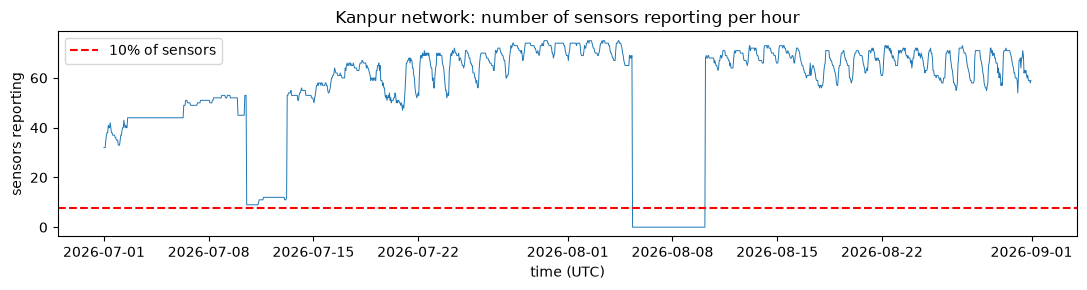

In [6]:
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(n_reporting.index, n_reporting.values, lw=0.7)
ax.axhline(OUTAGE_SHARE * len(sensor_ids), color="r", ls="--", label="10% of sensors")
ax.set_ylabel("sensors reporting"); ax.set_xlabel("time (UTC)"); ax.legend()
ax.set_title("Kanpur network: number of sensors reporting per hour")
plt.tight_layout(); plt.show()

### Sensors that barely follow the rest of the network
For each sensor, correlate its `ok` hourly series with the **median of all other sensors** in the same hour
(leave-one-out, so a sensor isn't compared with itself). PM2.5 at city scale is driven by shared weather,
so a healthy sensor should track the network.

count    74.000
mean      0.693
std       0.137
min       0.256
25%       0.624
50%       0.711
75%       0.794
max       0.872

Sensors with correlation < 0.5:
U8APQDBX        0.256
1203260075      0.362
TUOBZVJ0        0.365
1204260025      0.373
AC0BFBE34CC7    0.389
1203260084      0.406
1203260125      0.461
1204260010      0.490


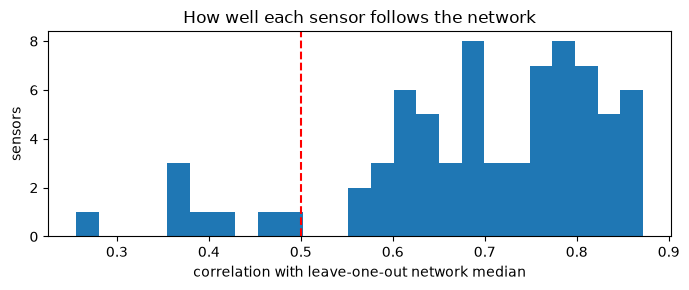

In [7]:
ok = hourly[hourly.flag == "ok"].pivot(index="timestamp_utc", columns="sensor_id", values="pm25")
track = {}
for s in ok.columns:
    others = ok.drop(columns=s).median(axis=1)
    both = pd.concat([ok[s], others], axis=1).dropna()
    track[s] = both.corr().iloc[0, 1] if len(both) >= 100 else np.nan
track = pd.Series(track, name="corr_with_network").sort_values()
print(track.describe().round(3).to_string())
TRACK_THRESHOLD = 0.5
poor = track[track < TRACK_THRESHOLD]
print(f"\nSensors with correlation < {TRACK_THRESHOLD}:")
print(poor.round(3).to_string())
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(track.dropna(), bins=25); ax.axvline(TRACK_THRESHOLD, color="r", ls="--")
ax.set_xlabel("correlation with leave-one-out network median"); ax.set_ylabel("sensors")
ax.set_title("How well each sensor follows the network"); plt.tight_layout(); plt.show()

Threshold 0.5: a correlation below 0.5 means the sensor shares less than 25% of its variance (r² < 0.25)
with the rest of the city. That is well below the network's lower quartile (≈ 0.62; median ≈ 0.71).
These sensors are **reported, not flagged**: low correlation could also be genuine local sources
(a roadside or industrial site), so it is not proof of a fault on its own.

## 0.4 Write `kanpur_hourly_clean.csv`
Long hourly table: `sensor_id, timestamp_utc, latitude, longitude, pm25, flag, network_outage`.
Flagged values are kept (error-code hours have pm25 = NaN with flag `error_code`), and missing hours are not filled.

In [8]:
clean = hourly[["sensor_id", "timestamp_utc", "latitude", "longitude", "pm25", "flag", "network_outage"]].copy()
clean["timestamp_utc"] = clean.timestamp_utc.dt.strftime("%Y-%m-%d %H:%M")
clean.to_csv(OUT_CSV, index=False, float_format="%.3f")
print("wrote", OUT_CSV, clean.shape)
print(clean.flag.value_counts().to_string())

wrote kanpur_hourly_clean.csv (82131, 7)
flag
ok                79625
stuck              1693
dropped_sensor      600
error_code          136
zero                 49
spike                28


## 0.5 Calibration check between the two ID families
Pair each 10-digit sensor with its nearest 8-character sensor, if one is within 3 km
(distances in km use the assignment's local projection, re-centred on Kanpur).
Fit a linear correction 8-char ≈ a + b · 10-digit on **July** hours where both are `ok`, and test it on **August**.

In [9]:
pos = info.join(hourly.groupby("sensor_id")[["latitude", "longitude"]].first())
lat0, lon0 = pos.latitude.mean(), pos.longitude.mean()
pos["x_km"] = (pos.longitude - lon0) * 100.3
pos["y_km"] = (pos.latitude - lat0) * 110.6
usable = pos.index.difference(dropped)                     # dropped sensors have no ok readings
ten = pos.loc[usable][pos.loc[usable].family == "10-digit"]
eight = pos.loc[usable][pos.loc[usable].family == "8-char"]
pairs = []
for s, r in ten.iterrows():
    d = np.hypot(eight.x_km - r.x_km, eight.y_km - r.y_km)
    if d.min() <= 3.0:
        pairs.append({"sensor_10": s, "sensor_8": d.idxmin(), "dist_km": d.min()})
pairs = pd.DataFrame(pairs)
print(f"{len(pairs)} pairs within 3 km")

okw = hourly[hourly.flag == "ok"].pivot(index="timestamp_utc", columns="sensor_id", values="pm25")
P = []
for _, p in pairs.iterrows():
    both = okw[[p.sensor_10, p.sensor_8]].dropna()
    P.append(pd.DataFrame({"pair": f"{p.sensor_10}-{p.sensor_8}", "t": both.index,
                           "x10": both[p.sensor_10].values, "y8": both[p.sensor_8].values}))
P = pd.concat(P, ignore_index=True)
jul, aug = P[P.t.dt.month == 7], P[P.t.dt.month == 8]
b, a = np.polyfit(jul.x10, jul.y8, 1)
print(f"Correction fitted on July ({len(jul)} paired hours): 8-char ≈ {a:.2f} + {b:.3f} × 10-digit")


def disagreement(x, y):
    e = x - y
    return {"bias": e.mean(), "MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean())}


off = (jul.y8 - jul.x10).mean()             # offset-only correction (no slope)
print(f"Offset-only alternative fitted on July: 8-char ≈ 10-digit + {off:.2f}")
tab = pd.DataFrame({
    "July raw": disagreement(jul.x10, jul.y8),
    "July linear": disagreement(a + b * jul.x10, jul.y8),
    "July offset": disagreement(jul.x10 + off, jul.y8),
    "Aug raw": disagreement(aug.x10, aug.y8),
    "Aug linear": disagreement(a + b * aug.x10, aug.y8),
    "Aug offset": disagreement(aug.x10 + off, aug.y8)}).T
print(tab.round(2).to_string())
per_pair = pd.DataFrame({k: {"raw_MAE": (g.x10 - g.y8).abs().mean(), "corr_MAE": (a + b * g.x10 - g.y8).abs().mean(),
                             "corr": g[["x10", "y8"]].corr().iloc[0, 1], "n": len(g)}
                         for k, g in aug.groupby("pair")}).T
print("\nAugust, per pair:"); print(per_pair.round(2).to_string())

21 pairs within 3 km
Correction fitted on July (7801 paired hours): 8-char ≈ 26.83 + 0.291 × 10-digit
Offset-only alternative fitted on July: 8-char ≈ 10-digit + 1.33
             bias    MAE   RMSE
July raw    -1.33  11.28  21.00
July linear  0.00  11.08  16.89
July offset  0.00  11.36  20.96
Aug raw     -1.77  12.22  21.92
Aug linear  -1.12  14.68  22.40
Aug offset  -0.44  12.34  21.85

August, per pair:
                     raw_MAE  corr_MAE  corr      n
1203260063-BEQBDBTZ    19.20     19.56  0.42  626.0
1203260066-BPVCUQ5W    14.36     17.53  0.59  621.0
1203260067-DNYU7SEW    16.32     18.43  0.79  607.0
1203260075-BEQBDBTZ    19.70     18.08  0.24  430.0
1203260078-CTU30PGT     6.38      9.86  0.79  613.0
1203260081-DDJMYBH3     9.93     14.52  0.61  625.0
1203260086-OROLHDYZ     8.14     13.28  0.81  622.0
1203260128-04TGTKIS    12.63     14.59  0.78  477.0
1203260143-7HZBUU8B     7.11     13.24  0.76   89.0
1203260144-UGYZAWR7     9.72     12.86  0.80  390.0
1203260148-04TGTKI

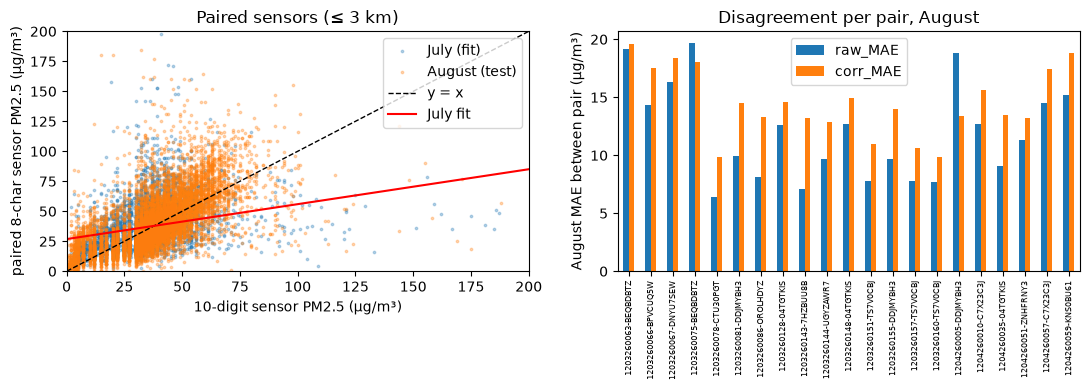

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(jul.x10, jul.y8, s=3, alpha=0.3, label="July (fit)")
ax[0].scatter(aug.x10, aug.y8, s=3, alpha=0.3, label="August (test)")
xx = np.linspace(0, 200, 10)
ax[0].plot(xx, xx, "k--", lw=1, label="y = x"); ax[0].plot(xx, a + b * xx, "r", lw=1.5, label="July fit")
ax[0].set_xlim(0, 200); ax[0].set_ylim(0, 200)
ax[0].set_xlabel("10-digit sensor PM2.5 (µg/m³)"); ax[0].set_ylabel("paired 8-char sensor PM2.5 (µg/m³)")
ax[0].legend(); ax[0].set_title("Paired sensors (≤ 3 km)")
per_pair[["raw_MAE", "corr_MAE"]].plot.bar(ax=ax[1]); ax[1].set_ylabel("August MAE between pair (µg/m³)")
ax[1].set_title("Disagreement per pair, August"); ax[1].tick_params(axis="x", labelsize=6)
plt.tight_layout(); plt.show()

**Interpretation (numbers in the table above):**
- **The two families agree on average.** The raw bias is only about −1 to −2 µg/m³, so there is little systematic
  calibration offset to remove. The offset-only correction therefore changes almost nothing.
- **The fitted linear slope is far below 1 (≈ 0.3).** This is *regression dilution*: when the predictor (the 10-digit
  sensor) is itself noisy, least squares shrinks the slope toward 0, so the "correction" mostly pulls everything toward
  the July mean. That lowers July RMSE (the squared-error criterion it was fitted on), but it **increases** August
  MAE for most pairs. A fit that improves the training month and hurts the test month is exactly why we test on August.
- **Most of the pairwise disagreement is not calibration.** Pairs are up to 3 km apart and see different local sources;
  the 10-digit sensors have 1 µg/m³ resolution; and both have independent noise. Correlations within pairs are only
  ≈ 0.4–0.85, and a single global linear map cannot fix that.

**Conclusion:** no cross-family correction is applied to the clean file. The test shows the correction does not
generalise from July to August.

## 0.6 Before / after summary and the daily cycle (IST)

In [11]:
grid_15 = len(raw) * len(sensor_ids)
before = {"sensors": len(sensor_ids), "readings": len(long_raw),
          "share_missing_%": 100 * (1 - len(long_raw) / grid_15)}
hourly_grid = len(all_hours) * len(sensor_ids)
ok_rows = hourly[hourly.flag == "ok"]
after = {"sensors": ok_rows.sensor_id.nunique(), "readings": len(ok_rows),
         "share_missing_%": 100 * (1 - len(ok_rows) / hourly_grid)}
mid = {"sensors": hourly.sensor_id.nunique(), "readings": int(hourly.pm25.notna().sum()),
       "share_missing_%": 100 * (1 - hourly.pm25.notna().sum() / hourly_grid)}
bt = pd.DataFrame({"raw (15-min grid)": before, "hourly, before flagging": mid, "hourly, flag == ok": after}).T
bt["sensors"] = bt.sensors.astype(int); bt["readings"] = bt.readings.astype(int)
print(bt.round(1).to_string())

                         sensors  readings  share_missing_%
raw (15-min grid)             76     85762             81.0
hourly, before flagging       76     81995             27.5
hourly, flag == ok            74     79625             29.6


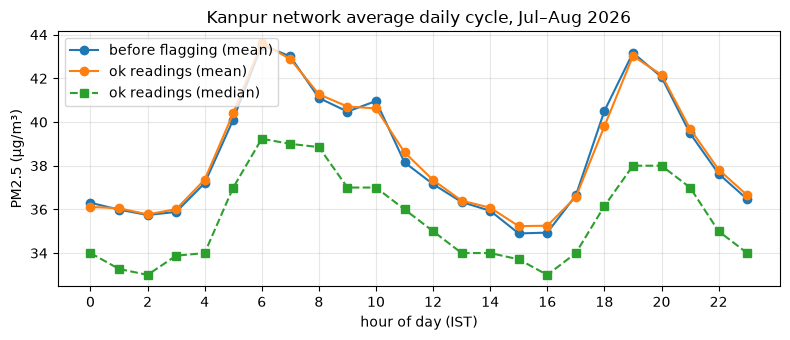

peak hour (IST, ok mean): 6 | lowest hour: 15


In [12]:
IST = pd.Timedelta(hours=5, minutes=30)
h_ist_all = (hourly.timestamp_utc + IST).dt.hour
h_ist_ok = (ok_rows.timestamp_utc + IST).dt.hour
cycle_raw = hourly.pm25.groupby(h_ist_all).mean()
cycle_ok = ok_rows.groupby(h_ist_ok).pm25.mean()
cycle_med = ok_rows.groupby(h_ist_ok).pm25.median()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(cycle_raw.index, cycle_raw.values, "o-", label="before flagging (mean)")
ax.plot(cycle_ok.index, cycle_ok.values, "o-", label="ok readings (mean)")
ax.plot(cycle_med.index, cycle_med.values, "s--", label="ok readings (median)")
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("hour of day (IST)"); ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title("Kanpur network average daily cycle, Jul–Aug 2026"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("peak hour (IST, ok mean):", int(cycle_ok.idxmax()), "| lowest hour:", int(cycle_ok.idxmin()))

PM2.5 peaks overnight and in the early morning, when the boundary layer is shallow and pollution is trapped
near the ground. It drops to a minimum in the afternoon, when daytime mixing dilutes it.
Before flagging, the 999 codes and spikes inflate the mean. After cleaning, the cycle is smoother and lower.